# 🐶 5kg 소형견 닭 알러지 제외(Chicken-Free) 간식 30종 데이터 분석 보고서

본 주피터 노트북은 프로젝트 스코프에 설치된 `k-skill` 쇼핑 스킬(`danawa-price-search`, `market-kurly-search`)을 통해 수집한 **[dog_treats_no_chicken_candidates.csv](./dog_treats_no_chicken_candidates.csv)** (총 30개 후보 상품) 데이터를 기반으로 정량적 가격·가성비·인기도·알러지 안전성 분석을 수행합니다.

### 🎯 분석 배경 및 핵심 기준
1. **급여 대상**: 5kg 소형견 (한 입 크기, 소프트 식감, 쉽게 잘라 줄 수 있는 슬라이스/큐브/트릿, 소형견용 덴탈껌 우대)
2. **알러지 제약**: **닭고기(계육·치킨·사사미·닭근위 등) 전량 배제** 및 원재료 투명성에 따른 안전등급 분류
3. **평가 축**:
   - **알러지 안전성 (35점)**: 단일원물 100%, 가수분해 단백질, 식물성/유제품 단일원료 우대
   - **대중 인기도 (35점)**: 다나와·마켓컬리 누적 리뷰 수(Log 스케일) 및 평점 반영
   - **단위 가성비 (30점)**: 총 중량 대비 **10g당 환산 단가(원)** 및 무료배송/샛별배송 실구매가 효율 반영


In [1]:
import re
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 1. CSV 데이터 로드 및 정량 분석용 파생 변수 생성
df = pd.read_csv("dog_treats_no_chicken_candidates.csv", encoding="utf-8-sig")

WEIGHT_MAP_G = {
    1: 1000, 2: 70, 3: 60, 4: 90, 5: 100,
    6: 40, 7: 100, 8: 300, 9: 1000, 10: 400,
    11: 300, 12: 50, 13: 50, 14: 500, 15: 120,
    16: 300, 17: 270, 18: 160, 19: 55, 20: 80,
    21: 40, 22: 30, 23: 23, 24: 300, 25: 250,
    26: 40, 27: 50, 28: 27, 29: 100, 30: 300
}

def parse_protein_group(row):
    comb = f"{row['카테고리']} {row['주원료_단백질']}"
    if any(k in comb for k in ["가수분해", "덴탈", "목뼈", "힘줄", "꽈배기"]):
        return "덴탈/천연껌(가수분해·오리·칠면조)"
    if any(k in comb for k in ["황태", "북어", "연어", "어류"]):
        return "어류(황태·북어·연어)"
    if "오리" in comb:
        return "오리고기(안심·말이)"
    if any(k in comb for k in ["한우", "소고기", "말고기", "양고기"]):
        return "적색육(한우·말·양고기)"
    return "식물성/치즈(고구마·두부·치즈)"

def parse_safety_tier(s):
    s = str(s)
    if "성분표확인권장" in s: return "주의(성분표 확인 권장)"
    if "단일원물" in s: return "최상(단일원물 100%)"
    if "가수분해" in s: return "최상(가수분해 저알러지)"
    if "식물성" in s or "유제품" in s: return "최상(식물성/유제품)"
    return "안심(무계육 복합원료)"

def parse_reviews(s):
    s = str(s)
    if "9,999+" in s: return 10000
    if "999+" in s: return 1000
    m = re.search(r"리뷰\s*([0-9,]+)건", s)
    return int(m.group(1).replace(",", "")) if m else 30

df["플랫폼"] = df["조사_스킬_출처"].apply(lambda s: "마켓컬리" if "market-kurly" in str(s) else "다나와 가격비교")
df["단백질_그룹"] = df.apply(parse_protein_group, axis=1)
df["안전등급_분류"] = df["닭알러지_안전등급"].apply(parse_safety_tier)
df["중량_g"] = df["번호"].map(WEIGHT_MAP_G)
df["10g당_단가_원"] = (df["최저가_할인가_원"] / (df["중량_g"] / 10.0)).round(0).astype(int)
df["리뷰수_수치"] = df["인기도_리뷰_평점"].apply(parse_reviews)

# 100점 만점 종합 추천 점수 산출: 알러지 안전성(35점) + 인기도(35점) + 10g당 가성비(30점)
safety_map = {"최상(단일원물 100%)": 35, "최상(가수분해 저알러지)": 35, "최상(식물성/유제품)": 35, "안심(무계육 복합원료)": 30, "주의(성분표 확인 권장)": 15}
df["점수_안전성"] = df["안전등급_분류"].map(safety_map)
df["점수_인기도"] = (np.log10(df["리뷰수_수치"] + 1) / math.log10(10001) * 35.0).round(1)
log_u = np.log10(df["10g당_단가_원"].clip(lower=40))
df["점수_가성비"] = ((log_u.max() - log_u) / (log_u.max() - log_u.min()) * 25.0 + 5.0).round(1)
df["종합추천점수"] = (df["점수_안전성"] + df["점수_인기도"] + df["점수_가성비"]).round(1)

print(f"총 분석 대상 상품 수: {len(df)}종 (안심 등급: {(df['점수_안전성']>=30).sum()}종)")
df[["번호", "플랫폼", "단백질_그룹", "상품명", "최저가_할인가_원", "10g당_단가_원", "리뷰수_수치", "종합추천점수"]].head(10)


총 분석 대상 상품 수: 30종


번호,조사_스킬_출처,카테고리,브랜드,상품명,주원료_단백질,최저가_할인가_원,단위당_가성비,인기도_리뷰_평점
1,danawa-price-search (다나와 가격비교),북어/황태 동결건조,벨버드,벨버드 시간순삭 황태 큐브 1kg (대용량),황태(북어) 100%,15220,10g당 약 111~152원 (초특급 대용량 가성비),별점 4.6 / 리뷰 719건 (카테고리 인기 2위)
2,market-kurly-search (마켓컬리),연어 동결건조 트릿,골드로니,[골드로니] YES I'M Real 생 알래스카 연어 트릿 강아지간식,알래스카 연어 100%,11475,36% 대폭 할인가,리뷰 294건
3,market-kurly-search (마켓컬리),황태 건조간식,스위피(어글어글),[스위피] 어글어글 DOG 바삭 건조 황태채,건조 황태 100%,9720,19% 할인가,리뷰 726건
4,market-kurly-search (마켓컬리),황태/생선 스낵,케이헬스케어,[케이헬스케어] 멍태깡 강아지 간식 90g,황태(명태),3400,10g당 378원 (32% 할인가),리뷰 81건
5,danawa-price-search (다나와 가격비교),연어+고구마 스틱,한입뚝딱,한입뚝딱 연어&브로콜리 고구마 말이 스틱 100g (6p),연어 + 고구마 + 브로콜리,4160,1개당 693원 (카테고리 인기 1위),별점 4.9 / 리뷰 133건 (카테고리 인기 1위)
6,market-kurly-search (마켓컬리),오리안심 수제육포,복슬강아지,[복슬강아지] 국내산 무항생제 오리안심 육포 40g,국내산 무항생제 오리안심 100%,4590,"10g당 1,148원 (25% 할인가)","리뷰 9,999+건 (컬리 반려견 간식 최다 리뷰 1위)"
7,market-kurly-search (마켓컬리),오리안심 수제간식,골드로니,[골드로니] YES I'M Real 소화안심 오리안심 강아지고양이간식,국내산 오리안심 100%,12750,36% 대폭 할인가,리뷰 958건
8,danawa-price-search (다나와 가격비교),오리+고구마 말이,채널펫,채널펫 건강한 간식 순살듬뿍 고구마 오리 말이 300g,오리고기 + 고구마,9350,10g당 312원,별점 4.9 / 리뷰 999+건 (다나와 베스트셀러)
9,danawa-price-search (다나와 가격비교),오리안심 대용량,마마쇼,마마쇼 독 오리 말이 스틱 1kg (대용량),오리고기,10790,10g당 108원 (무료배송 1kg 가성비 최고),별점 4.7 / 리뷰 157건
10,danawa-price-search (다나와 가격비교),오리안심 슬라이스,피에스코리아(홈쿡),피에스코리아 홈쿡 오리 안심 슬라이스 400g,오리안심,6560,10g당 약 164원 (무료배송 기준 237원),다나와 인기 오리슬라이스


## 2. 파생 변수 생성 및 단백질 그룹별 기초 통계량 (EDA)

상품마다 용량(23g 소포장부터 1kg 대용량까지)이 다르므로 공정한 가성비 비교를 위해 **중량(g) 기준 10g당 단가(원)**, **리뷰 수 수치화**, 그리고 **단백질 그룹별 요약 통계**를 산출합니다.


In [2]:
# 단백질 그룹별 가격·단가·리뷰 요약 통계
grp_summary = df.groupby("단백질_그룹").agg(
    상품수=("번호", "count"),
    최저가_평균_원=("최저가_할인가_원", lambda x: int(x.mean())),
    최저가_중앙값_원=("최저가_할인가_원", lambda x: int(x.median())),
    단가_10g당_평균_원=("10g당_단가_원", lambda x: int(x.mean())),
    단가_10g당_중앙값_원=("10g당_단가_원", lambda x: int(x.median())),
    평균_리뷰수=("리뷰수_수치", lambda x: int(x.mean())),
    종합추천점수_평균=("종합추천점수", lambda x: round(x.mean(), 1))
).reset_index().sort_values("단가_10g당_중앙값_원")

grp_summary


단백질_그룹,상품수,최저가_평균_원,최저가_중앙값_원,단가_10g당_평균_원,단가_10g당_중앙값_원,평균_리뷰수,종합추천점수_평균
덴탈/천연껌(가수분해·오리·칠면조),7,8962,9790,645,363,295,67.4
어류(황태·북어·연어),6,7692,6940,713,397,354,69.4
식물성/치즈(고구마·두부·치즈),4,2837,2850,641,649,458,72.2
적색육(한우·말·양고기),6,4263,3060,840,1122,688,66.7
오리고기(안심·말이),7,8222,7650,815,1148,2020,70.7


## 3. 단백질 그룹별 10g당 단가 및 평균 상품 가격 시각화

- **대용량 가성비 우위**: 다나와 가격비교의 대용량 간식(황태큐브 1kg, 오리말이 스틱 1kg, 고구마말랭이 250g 등)이 포함된 그룹은 **10g당 100~300원대**로 압도적인 가성비를 보입니다.
- **소포장 프리미엄 수제간식**: 마켓컬리의 국내산 무항생제 오리안심·한우간·말져키·칠면조힘줄은 40~55g 소포장 위주여서 10g당 단가는 1,100~2,200원대지만, **구매 1회당 지출 금액은 3,000~9,000원대**로 부담이 적고 신선도·기호성이 매우 높습니다.


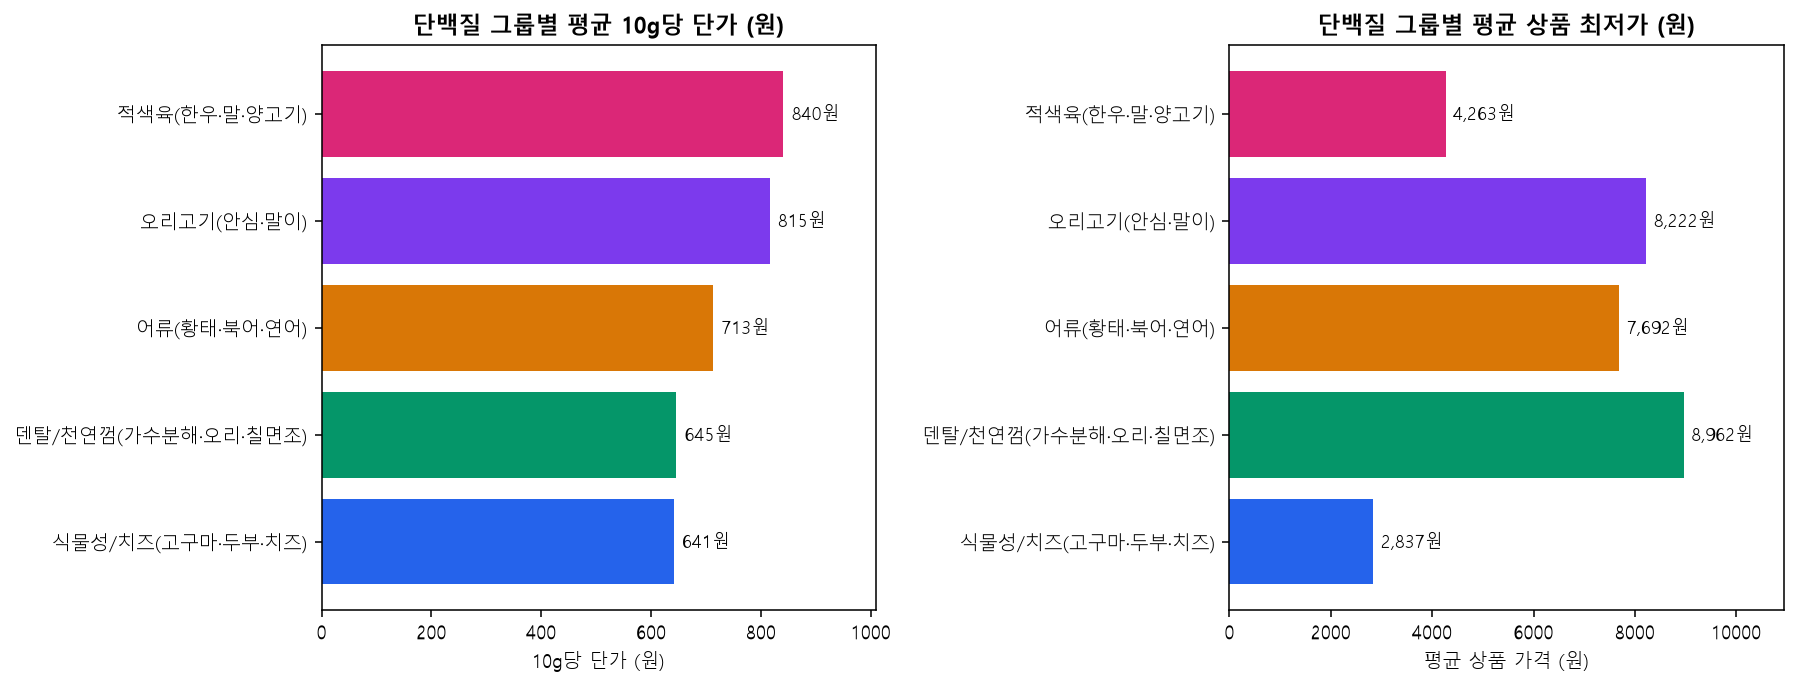

In [3]:
# 단백질 그룹별 평균 10g당 단가 & 평균 최저가 비교 차트
fig1, axes1 = plt.subplots(1, 2, figsize=(13, 5))
grp_stats = df.groupby("단백질_그룹").agg(
    평균최저가=("최저가_할인가_원", "mean"),
    평균10g단가=("10g당_단가_원", "mean")
).reset_index().sort_values("평균10g단가")

colors1 = ["#2563eb", "#059669", "#d97706", "#7c3aed", "#db2777"]
axes1[0].barh(grp_stats["단백질_그룹"], grp_stats["평균10g단가"], color=colors1)
axes1[0].set_title("단백질 그룹별 평균 10g당 단가 (원)", fontsize=12, fontweight="bold")
axes1[0].set_xlabel("10g당 단가 (원)")
for i, v in enumerate(grp_stats["평균10g단가"]):
    axes1[0].text(v + 15, i, f"{int(v):,}원", va="center", fontsize=9)
axes1[0].set_xlim(0, max(grp_stats["평균10g단가"]) * 1.22)

axes1[1].barh(grp_stats["단백질_그룹"], grp_stats["평균최저가"], color=colors1)
axes1[1].set_title("단백질 그룹별 평균 상품 최저가 (원)", fontsize=12, fontweight="bold")
axes1[1].set_xlabel("평균 상품 가격 (원)")
for i, v in enumerate(grp_stats["평균최저가"]):
    axes1[1].text(v + 150, i, f"{int(v):,}원", va="center", fontsize=9)
axes1[1].set_xlim(0, max(grp_stats["평균최저가"]) * 1.22)
fig1.tight_layout()
plt.show()


## 4. 가성비(10g당 단가) vs 인기도(리뷰 수) 포지셔닝 맵

X축(왼쪽일수록 10g당 단가가 저렴)과 Y축(위쪽일수록 리뷰 수가 많음, Log 스케일)을 교차 분석하면 **'고인기·고가성비 Sweet Spot'** 상품을 한눈에 식별할 수 있습니다.


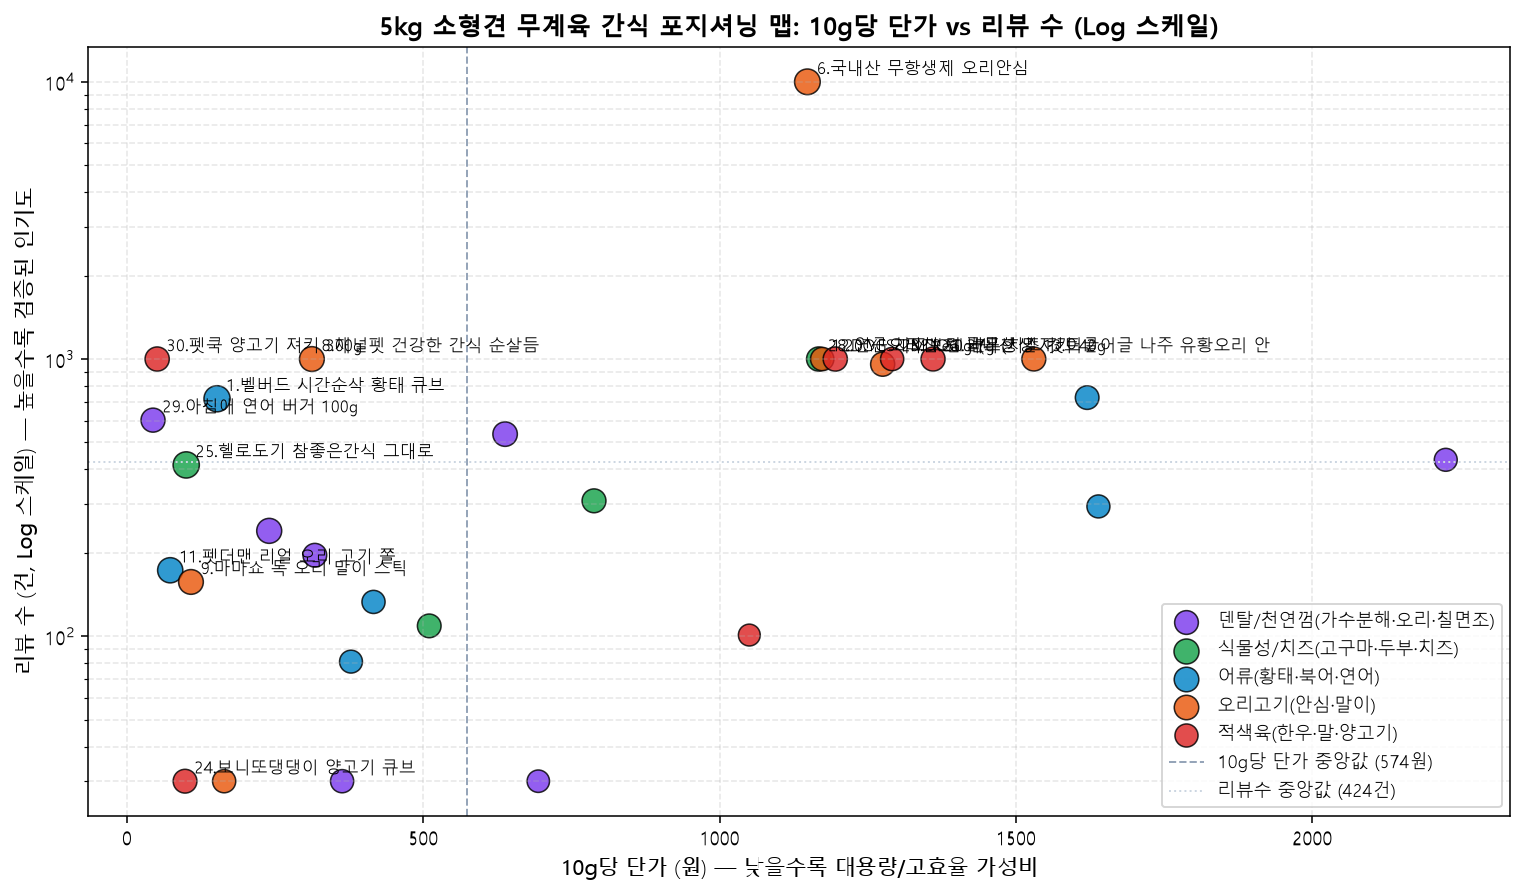

In [4]:
# 가성비(10g당 단가) vs 인기도(리뷰 수 Log 스케일) 버블 포지셔닝 맵
fig2, ax2 = plt.subplots(figsize=(11, 6.5))
palette = {
    "어류(황태·북어·연어)": "#0284c7",
    "오리고기(안심·말이)": "#ea580c",
    "덴탈/천연껌(가수분해·오리·칠면조)": "#7c3aed",
    "적색육(한우·말·양고기)": "#dc2626",
    "식물성/치즈(고구마·두부·치즈)": "#16a34a"
}
for p_grp, sub in df.groupby("단백질_그룹"):
    ax2.scatter(
        sub["10g당_단가_원"], sub["리뷰수_수치"],
        s=sub["종합추천점수"] * 2.2, c=palette.get(p_grp, "#64748b"),
        alpha=0.82, edgecolors="black", linewidth=0.8, label=p_grp
    )

ax2.set_yscale("log")
ax2.set_title("5kg 소형견 무계육 간식 포지셔닝 맵: 10g당 단가 vs 리뷰 수 (Log 스케일)", fontsize=13, fontweight="bold")
ax2.set_xlabel("10g당 단가 (원) — 낮을수록 대용량/고효율 가성비", fontsize=11)
ax2.set_ylabel("리뷰 수 (건, Log 스케일) — 높을수록 검증된 인기도", fontsize=11)
ax2.axvline(df["10g당_단가_원"].median(), color="#94a3b8", linestyle="--", linewidth=1, label=f"10g당 단가 중앙값 ({int(df['10g당_단가_원'].median()):,}원)")
ax2.axhline(df["리뷰수_수치"].median(), color="#cbd5e1", linestyle=":", linewidth=1, label=f"리뷰수 중앙값 ({int(df['리뷰수_수치'].median()):,}건)")

for _, r in df.iterrows():
    if r["종합추천점수"] >= 76 or r["10g당_단가_원"] <= 115 or r["리뷰수_수치"] >= 1000:
        short_name = re.sub(r"^\[.*?\]\s*", "", r["상품명"])[:14]
        ax2.annotate(f"{r['번호']}.{short_name}", (r["10g당_단가_원"], r["리뷰수_수치"]), textcoords="offset points", xytext=(5, 4), fontsize=8.5)

ax2.legend(loc="lower right", fontsize=9)
ax2.grid(True, which="both", linestyle="--", alpha=0.3)
fig2.tight_layout()
plt.show()


## 5. 5kg 소형견 맞춤 종합 추천 스코어링 TOP 12 결과

5kg 소형견에게 닭 알러지 걱정 없이 급여할 수 있도록 **안전성(35점) + 인기도(35점) + 10g당 가성비(30점)** 합산 점수로 상위 12개 상품을 도출했습니다.


번호,플랫폼,단백질_그룹,상품명,안전등급_분류,최저가_할인가_원,10g당_단가_원,리뷰수_수치,종합추천점수
25,다나와 가격비교,식물성/치즈(고구마·두부·치즈),헬로도기 참좋은간식 그대로 말랑 고구마 스틱 250g,최상(단일원물 100%),2500,100,415,82.7
1,다나와 가격비교,어류(황태·북어·연어),벨버드 시간순삭 황태 큐브 1kg (대용량),최상(단일원물 100%),15220,152,719,82.1
6,마켓컬리,오리고기(안심·말이),[복슬강아지] 국내산 무항생제 오리안심 육포 40g,최상(단일원물 100%),4590,1148,10000,79.2
11,다나와 가격비교,어류(황태·북어·연어),펫더맨 리얼 오리 고기 쫄깃쫄깃 오리 연어포 300g,안심(무계육 복합원료),2180,73,173,76.4
14,다나와 가격비교,덴탈/천연껌(가수분해·오리·칠면조),빈즈라이크 깨끗한 간식 오리 목뼈 500g,최상(단일원물 100%),12000,240,240,75.0
8,다나와 가격비교,오리고기(안심·말이),채널펫 건강한 간식 순살듬뿍 고구마 오리 말이 300g,안심(무계육 복합원료),9350,312,1000,73.8
9,다나와 가격비교,오리고기(안심·말이),마마쇼 독 오리 말이 스틱 1kg (대용량),안심(무계육 복합원료),10790,108,157,73.5
15,마켓컬리,덴탈/천연껌(가수분해·오리·칠면조),[골드로니] YES I'M Real 바샤삭 오리목뼈 강아지간식,최상(단일원물 100%),7650,638,536,71.9
30,다나와 가격비교,적색육(한우·말·양고기),펫쿡 양고기 져키 300g,주의(성분표 확인 권장),1520,51,1000,70.4
28,마켓컬리,식물성/치즈(고구마·두부·치즈),[네츄럴코어] DOG 치즈브림 27g (저염 숙성치즈),최상(식물성/유제품),3150,1167,1000,70.4


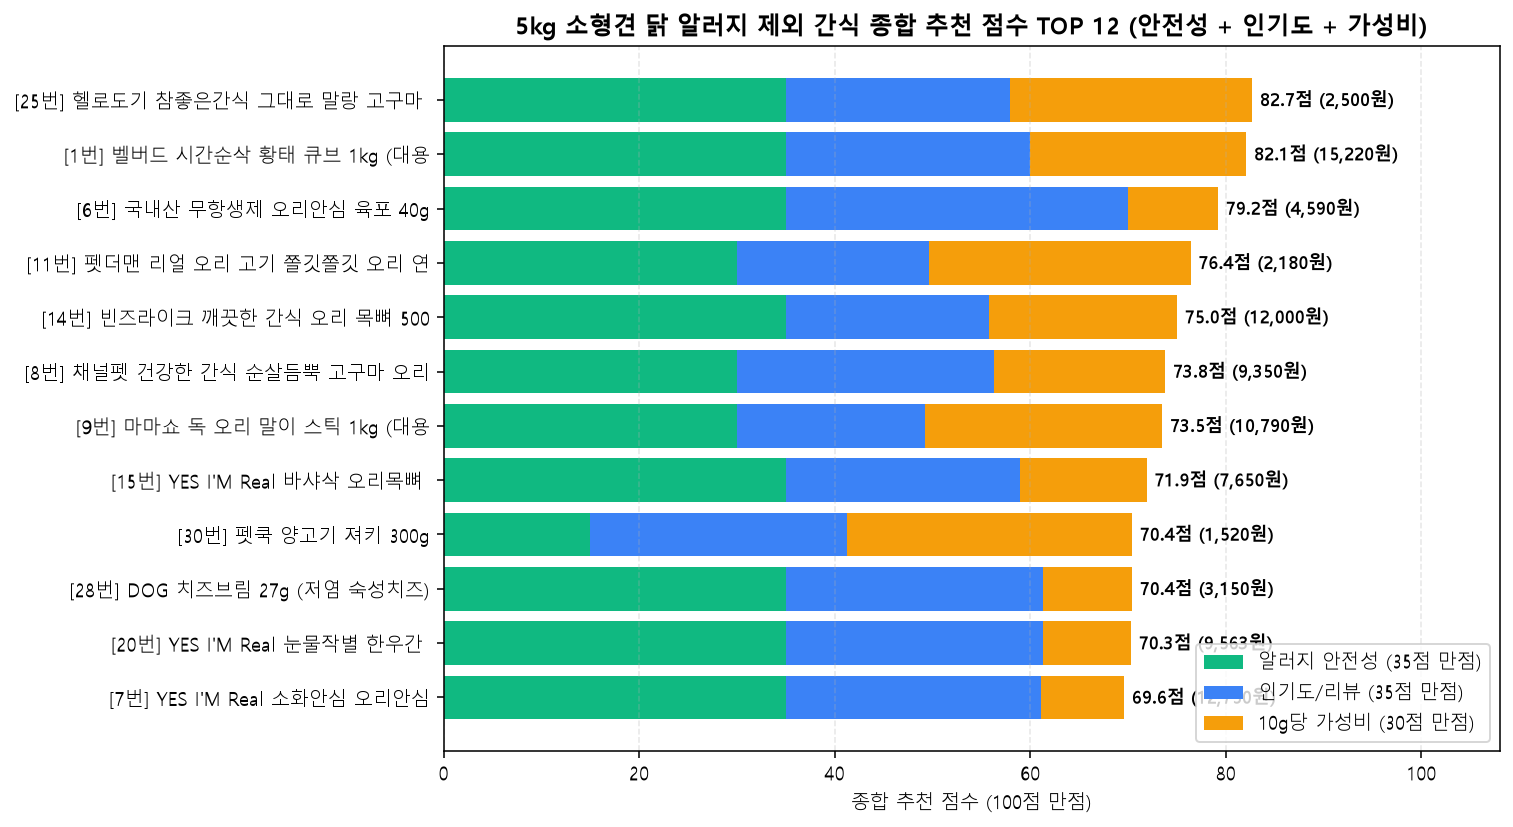

In [5]:
# 종합 추천 점수 상위 12개 상품 테이블 및 누적 바 차트
top12 = df.sort_values("종합추천점수", ascending=False).head(12)
display_cols = ["번호", "플랫폼", "단백질_그룹", "상품명", "안전등급_분류", "최저가_할인가_원", "10g당_단가_원", "리뷰수_수치", "종합추천점수"]

fig3, ax3 = plt.subplots(figsize=(11, 6))
top12_rev = top12.iloc[::-1]
short_labels = [f"[{r['번호']}번] {re.sub(r'^\[.*?\]\s*', '', r['상품명'])[:22]}" for _, r in top12_rev.iterrows()]
ax3.barh(short_labels, top12_rev["점수_안전성"], label="알러지 안전성 (35점 만점)", color="#10b981")
ax3.barh(short_labels, top12_rev["점수_인기도"], left=top12_rev["점수_안전성"], label="인기도/리뷰 (35점 만점)", color="#3b82f6")
ax3.barh(short_labels, top12_rev["점수_가성비"], left=top12_rev["점수_안전성"] + top12_rev["점수_인기도"], label="10g당 가성비 (30점 만점)", color="#f59e0b")
for i, (_, r) in enumerate(top12_rev.iterrows()):
    ax3.text(r["종합추천점수"] + 0.8, i, f"{r['종합추천점수']:.1f}점 ({r['최저가_할인가_원']:,}원)", va="center", fontsize=9, fontweight="bold")
ax3.set_xlim(0, 108)
ax3.set_title("5kg 소형견 닭 알러지 제외 간식 종합 추천 점수 TOP 12 (안전성 + 인기도 + 가성비)", fontsize=12.5, fontweight="bold")
ax3.set_xlabel("종합 추천 점수 (100점 만점)")
ax3.legend(loc="lower right")
ax3.grid(axis="x", linestyle="--", alpha=0.3)
fig3.tight_layout()
plt.show()

top12[display_cols]


## 6. 결론 및 5kg 소형견 급여 목적별 최적 조합 (Portfolio)

1. **데일리 노즈워크·칭찬간식 (가성비 대용량 1위)**: **벨버드 시간순삭 황태 큐브 1kg (15,220원 무료배송, 10g당 152원)** — 황태 100% 단일원물로 닭 알러지 위험이 0%이며, 작고 가벼운 동결건조 큐브라 5kg 소형견에게 하루 여러 번 급여해도 칼로리·알러지 부담이 없습니다.
2. **소형견 최고 기호성 수제육포 (인기도 1위)**: **[복슬강아지] 무항생제 오리안심 육포 40g (4,590원, 리뷰 9,999+)** & **채널펫 순살듬뿍 고구마 오리말이 300g (9,350원, 리뷰 999+)** — 손으로 쉽게 찢어지는 식감으로 소형견 만족도가 가장 높습니다.
3. **치석케어 & 알러지 원천 차단 덴탈껌**: **무마진 독 소프트 덴탈껌 바나나 270g (9g×30개입 9,790원, 개당 326원)** & **몰리스 웅자 오리 꽈배기껌 300g (9,520원, ★5.0)** — 가수분해 단백질 또는 오리 베이스로 닭 알러지를 피하면서 5kg 소형견 치아 크기에 딱 맞습니다.
4. **닭·오리 교차 알러지까지 걱정될 때 (초저알러지 스페셜)**: **[복슬강아지] 국내산 말져키 40g (5,440원)**, **[골드로니] 눈물작별 한우간 (9,563원)**, **헬로도기 그대로 말랑 고구마 스틱 250g (2,500원, 10g당 100원)**.
